In [1]:

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("Setup complete!")


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas: 2.2.3
Setup complete!


In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

folder = "/content/drive/MyDrive/FI2010_Project"

for name in os.listdir(folder):
    path = os.path.join(folder, name)
    print(name, round(os.path.getsize(path) / (1024**3), 2), "GB"
          if os.path.isfile(path) else "[folder]")


archive.zip 1.95 GB


In [6]:

import zipfile
import os

zip_path = os.path.join(folder, "archive.zip")

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.infolist()
    print("Total entries:", len(files))
    print("First 60 entries:")

    for f in files[:60]:
        print(f.filename, round(f.file_size / (1024**2), 2), "MB")


Total entries: 108
First 60 entries:
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_1.txt 102.57 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_2.txt 76.66 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_3.txt 98.34 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_4.txt 93.61 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_5.txt 107.43 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_6.txt 102.54 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_7.txt 136.35 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_8.txt 131.76 MB
BenchmarkDatasets/Auction/1.Auction_Zscore/Auction_Zscore_Testing/Test_Dst_Auction_ZScore_CF_9

In [7]:

import os
import zipfile

# Locate the ZIP in your Google Drive project folder
folder = "/content/drive/MyDrive/FI2010_Project"
zip_files = [
    os.path.join(folder, f)
    for f in os.listdir(folder)
    if f.lower().endswith(".zip")
]

zip_path = zip_files[0]

# Start with regular, non-auction trading data
target = (
    "BenchmarkDatasets/NoAuction/"
    "1.NoAuction_Zscore/NoAuction_Zscore_Testing/"
    "Test_Dst_NoAuction_ZScore_CF_1.txt"
)

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(target) as f:
        for i in range(3):
            line = f.readline().decode("utf-8", errors="replace")
            print(f"\nLINE {i+1}:")
            print(line[:1000])
            print("Characters:", len(line))

print("\nInspection complete.")



LINE 1:
   4.8382630e-01   4.8382630e-01   4.8280533e-01   4.8280533e-01   4.8280533e-01   4.8280533e-01   4.8280533e-01   4.8280533e-01   4.8280533e-01   4.8280533e-01   4.8178436e-01   4.8178436e-01   4.8178436e-01   4.8178436e-01   4.8178436e-01   4.8178436e-01   4.8178436e-01   4.8178436e-01   4.8178436e-01   4.8076339e-01   4.8076339e-01   4.8076339e-01   4.7872145e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7667952e-01   4.7667952e-01   4.7667952e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7770049e-01   4.7667952e-01   4.7667952e-01   4.7667952e-01   4.7667952e-01   4.7667952e-01   4.7974242e-01   4.7974242e-01   4.7872145e-01   4.8076339e-01   4.7974242e-01   4.7667952e-01   4.7872145e-01   4.7770049e-01   4.7667952e-01   4.8382630e-01   4.7872145e-01   4.7974242e-01   4.7872145e-01   4.7974242e-0

In [8]:

import zipfile
import os
import numpy as np

target = (
    "BenchmarkDatasets/NoAuction/"
    "1.NoAuction_Zscore/NoAuction_Zscore_Testing/"
    "Test_Dst_NoAuction_ZScore_CF_1.txt"
)

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(target) as f:
        row_count = 0
        first_row_columns = None
        sample_rows = []

        for line in f:
            row_count += 1

            if row_count <= 3:
                values = np.fromstring(
                    line.decode("utf-8"), sep=" "
                )
                sample_rows.append(values[:5].tolist())

                if row_count == 1:
                    first_row_columns = len(
                        np.fromstring(
                            line.decode("utf-8"), sep=" "
                        )
                    )

        print("Total rows:", row_count)
        print("Values in first row:", first_row_columns)
        print("First 5 values of first 3 rows:")
        for i, row in enumerate(sample_rows, 1):
            print(f"Row {i}: {row}")


Total rows: 149
Values in first row: 38397
First 5 values of first 3 rows:
Row 1: [0.4838263, 0.4838263, 0.48280533, 0.48280533, 0.48280533]
Row 2: [-0.41186571, -0.41186571, -0.51541776, -0.18204697, -0.18204697]
Row 3: [0.48437571, 0.48437571, 0.48437571, 0.48437571, 0.48437571]


In [9]:

import numpy as np
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(target) as f:
        raw = np.loadtxt(f)

print("Original shape:", raw.shape)

# Convert to observations × features
data = raw.T

print("Transposed shape:", data.shape)
print("Input features:", data.shape[1] - 5)
print("Label columns:", 5)
print("Missing values:", np.isnan(data).sum())


Original shape: (149, 38397)
Transposed shape: (38397, 149)
Input features: 144
Label columns: 5
Missing values: 0


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(target) as f:
        raw = np.loadtxt(f)

# Separate the 144 input features from the 5 future-price labels
X = raw[:144, :].T
Y = raw[144:, :].T

print("Observations:", X.shape[0])
print("Input features:", X.shape[1])
print("Label horizons:", Y.shape[1])
print("Missing feature values:", np.isnan(X).sum())

# Inspect feature distributions
feature_summary = pd.DataFrame({
    "Mean": X.mean(axis=0),
    "Std Dev": X.std(axis=0),
    "Minimum": X.min(axis=0),
    "Maximum": X.max(axis=0)
})

print("\nFirst 10 feature summaries:")
display(feature_summary.head(10).round(4))

print("\nFuture label distributions:")
for j in range(Y.shape[1]):
    print(f"Horizon {j+1}:",
          dict(zip(*np.unique(Y[:, j], return_counts=True))))


Observations: 38397
Input features: 144
Label horizons: 5
Missing feature values: 0

First 10 feature summaries:


,Mean,Std Dev,Minimum,Maximum
0,0.1583,0.9932,-0.9741,1.3506
1,-0.1350,0.7627,-0.7446,15.3100
2,0.1581,0.9931,-0.9731,1.3537
3,-0.1831,0.5500,-0.6241,5.3425
4,0.1583,0.9932,-0.9742,1.3500
5,-0.0222,0.9186,-0.7778,12.7175
6,0.1581,0.9931,-0.9730,1.3543
7,-0.1000,0.7304,-0.7024,6.6363
8,0.1582,0.9931,-0.9743,1.3504
9,0.0874,1.0786,-0.8635,9.6259



Future label distributions:
Horizon 1: {np.float64(1.0): np.int64(8007), np.float64(2.0): np.int64(22699), np.float64(3.0): np.int64(7691)}
Horizon 2: {np.float64(1.0): np.int64(10200), np.float64(2.0): np.int64(18486), np.float64(3.0): np.int64(9711)}
Horizon 3: {np.float64(1.0): np.int64(11789), np.float64(2.0): np.int64(15564), np.float64(3.0): np.int64(11044)}
Horizon 4: {np.float64(1.0): np.int64(13764), np.float64(2.0): np.int64(11749), np.float64(3.0): np.int64(12884)}
Horizon 5: {np.float64(1.0): np.int64(16227), np.float64(2.0): np.int64(7049), np.float64(3.0): np.int64(15121)}


In [11]:

import pandas as pd
import numpy as np

summary = pd.DataFrame({
    "Feature": np.arange(1, 145),
    "Group": [
        "Core order book" if i < 40 else "Engineered"
        for i in range(144)
    ],
    "Mean": X.mean(axis=0),
    "Std": X.std(axis=0),
    "Min": X.min(axis=0),
    "Max": X.max(axis=0)
})

display(summary.groupby("Group").agg({
    "Mean": "mean",
    "Std": "mean",
    "Min": "min",
    "Max": "max"
}).round(4))

display(summary.head(40).round(4))


,Mean,Std,Min,Max
Group,,,,
Core order book,0.0581,0.9316,-0.9766,15.3100
Engineered,0.0523,1.0240,-98.4611,80.6106


,Feature,Group,Mean,Std,Min,Max
0,1,Core order book,0.1583,0.9932,-0.9741,1.3506
1,2,Core order book,-0.1350,0.7627,-0.7446,15.3100
2,3,Core order book,0.1581,0.9931,-0.9731,1.3537
3,4,Core order book,-0.1831,0.5500,-0.6241,5.3425
4,5,Core order book,0.1583,0.9932,-0.9742,1.3500
5,6,Core order book,-0.0222,0.9186,-0.7778,12.7175
6,7,Core order book,0.1581,0.9931,-0.9730,1.3543
7,8,Core order book,-0.1000,0.7304,-0.7024,6.6363
8,9,Core order book,0.1582,0.9931,-0.9743,1.3504
9,10,Core order book,0.0874,1.0786,-0.8635,9.6259


In [12]:

# Compare odd- and even-positioned features
# Python uses zero-based indexing.

for name, indices in [
    ("Odd-numbered features", np.arange(0, 40, 2)),
    ("Even-numbered features", np.arange(1, 40, 2))
]:
    block = X[:, indices]
    print(f"\n{name}")
    print("Mean of feature means:", round(block.mean(), 4))
    print("Mean feature standard deviation:",
          round(block.std(axis=0).mean(), 4))
    print("Overall minimum:", round(block.min(), 4))
    print("Overall maximum:", round(block.max(), 4))



Odd-numbered features
Mean of feature means: 0.1578
Mean feature standard deviation: 0.9929
Overall minimum: -0.9766
Overall maximum: 1.3587

Even-numbered features
Mean of feature means: -0.0417
Mean feature standard deviation: 0.8703
Overall minimum: -0.9009
Overall maximum: 15.31


In [13]:

import zipfile
import numpy as np

decp_path = (
    "BenchmarkDatasets/NoAuction/"
    "3.NoAuction_DecPre/NoAuction_DecPre_Testing/"
    "Test_Dst_NoAuction_DecPre_CF_1.txt"
)

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(decp_path) as f:
        decp = np.loadtxt(f)

print("Shape:", decp.shape)
print("\nFirst 10 values of the first 4 rows:")
print(decp[:4, :10])


Shape: (149, 38397)

First 10 values of the first 4 rows:
[[2.689e-01 2.689e-01 2.688e-01 2.688e-01 2.688e-01 2.688e-01 2.688e-01
  2.688e-01 2.688e-01 2.688e-01]
 [4.990e-03 4.990e-03 3.440e-03 8.430e-03 8.430e-03 4.990e-03 4.990e-03
  3.000e-03 4.990e-03 4.990e-03]
 [2.685e-01 2.685e-01 2.685e-01 2.685e-01 2.685e-01 2.685e-01 2.685e-01
  2.685e-01 2.685e-01 2.685e-01]
 [3.640e-03 3.640e-03 3.640e-03 3.640e-03 3.640e-03 3.640e-03 3.640e-03
  3.640e-03 2.860e-03 2.100e-04]]


In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# decp was loaded from the NoAuction DecPre testing file
data = decp[:144, :].T

# First 40 columns: ask price, ask size, bid price, bid size
# repeated for each of 10 levels
ask_prices = data[:, np.arange(0, 40, 4)]
ask_sizes  = data[:, np.arange(1, 40, 4)]
bid_prices = data[:, np.arange(2, 40, 4)]
bid_sizes  = data[:, np.arange(3, 40, 4)]

# Best prices are at level 1
best_ask = ask_prices[:, 0]
best_bid = bid_prices[:, 0]

mid_price = (best_ask + best_bid) / 2
spread = best_ask - best_bid
relative_spread = spread / mid_price

# Displayed depth across the 10 levels
ask_depth = ask_sizes.sum(axis=1)
bid_depth = bid_sizes.sum(axis=1)

# Relative order-book imbalance
denominator = bid_depth + ask_depth
imbalance = np.divide(
    bid_depth - ask_depth,
    denominator,
    out=np.full_like(bid_depth, np.nan),
    where=denominator != 0
)

metrics = pd.DataFrame({
    "mid_price": mid_price,
    "spread": spread,
    "relative_spread": relative_spread,
    "bid_depth": bid_depth,
    "ask_depth": ask_depth,
    "imbalance": imbalance
})

display(metrics.describe().round(6))
print("Non-positive spreads:", (spread <= 0).sum())
print("Invalid imbalance values:", np.isnan(imbalance).sum())



,mid_price,spread,relative_spread,bid_depth,ask_depth,imbalance
count,38397.000000,38397.000000,38397.000000,38397.000000,38397.000000,38397.000000
mean,0.236809,0.000421,0.001765,0.179697,0.171546,-0.002426
std,0.097191,0.000275,0.000866,0.146353,0.132728,0.214024
min,0.126050,0.000100,0.000283,0.009690,0.011600,-0.828754
25%,0.128750,0.000200,0.001151,0.051970,0.057720,-0.152258
50%,0.267350,0.000400,0.001584,0.093040,0.100950,-0.007222
75%,0.347800,0.000600,0.002312,0.291260,0.268290,0.141318
max,0.353650,0.003400,0.010413,0.812890,0.689020,0.720583


Non-positive spreads: 0
Invalid imbalance values: 0


In [15]:

# Check ordering of prices across the ten levels
# Based on our current proposed feature mapping.

ask_order_violations = np.mean(
    np.diff(ask_prices, axis=1) < 0
)

bid_order_violations = np.mean(
    np.diff(bid_prices, axis=1) > 0
)

crossed_quotes = np.mean(best_bid >= best_ask)

print("Ask-level ordering violations:",
      round(ask_order_violations * 100, 2), "%")
print("Bid-level ordering violations:",
      round(bid_order_violations * 100, 2), "%")
print("Crossed or locked best quotes:",
      round(crossed_quotes * 100, 2), "%")

print("\nFirst five observations:")
display(metrics.head().round(6))


Ask-level ordering violations: 0.0 %
Bid-level ordering violations: 0.0 %
Crossed or locked best quotes: 0.0 %

First five observations:


,mid_price,spread,relative_spread,bid_depth,ask_depth,imbalance
0,0.26870,0.0004,0.001489,0.02906,0.03783,-0.131111
1,0.26870,0.0004,0.001489,0.02906,0.03299,-0.063336
2,0.26865,0.0003,0.001117,0.02568,0.03416,-0.141711
3,0.26865,0.0003,0.001117,0.02755,0.05267,-0.313139
4,0.26865,0.0003,0.001117,0.02527,0.05267,-0.351552


In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the measures calculated from the DecPre file
df = metrics.copy()

# Define extreme order-book imbalance events
lower_cutoff = df["imbalance"].quantile(0.05)
upper_cutoff = df["imbalance"].quantile(0.95)

sell_side_candidates = np.flatnonzero(
    df["imbalance"].to_numpy() <= lower_cutoff
)
buy_side_candidates = np.flatnonzero(
    df["imbalance"].to_numpy() >= upper_cutoff
)

# Select non-overlapping events
def select_events(candidates, min_gap=31, margin=10, end_margin=20):
    selected = []
    last = -min_gap

    for i in candidates:
        if i >= margin and i < len(df) - end_margin:
            if i - last >= min_gap:
                selected.append(i)
                last = i

    return np.array(selected, dtype=int)

sell_events = select_events(sell_side_candidates)
buy_events = select_events(buy_side_candidates)

print("Lower 5% imbalance cutoff:", round(lower_cutoff, 4))
print("Upper 5% imbalance cutoff:", round(upper_cutoff, 4))
print("Selected negative-imbalance events:", len(sell_events))
print("Selected positive-imbalance events:", len(buy_events))

# Calculate event-time averages
window_before = 10
window_after = 20
relative_times = np.arange(-window_before, window_after + 1)

variables = [
    "mid_price", "relative_spread",
    "bid_depth", "ask_depth", "imbalance"
]

def event_study(event_indices):
    records = []

    for event in event_indices:
        for tau in relative_times:
            row = df.iloc[event + tau]
            records.append({
                "event": event,
                "tau": tau,
                **{v: row[v] for v in variables}
            })

    event_data = pd.DataFrame(records)
    return event_data.groupby("tau")[variables].mean()

sell_profile = event_study(sell_events)
buy_profile = event_study(buy_events)

print("\nNegative-imbalance event profile:")
display(sell_profile.round(6))

print("\nPositive-imbalance event profile:")
display(buy_profile.round(6))


Lower 5% imbalance cutoff: -0.3533
Upper 5% imbalance cutoff: 0.3583
Selected negative-imbalance events: 193
Selected positive-imbalance events: 172

Negative-imbalance event profile:


,mid_price,relative_spread,bid_depth,ask_depth,imbalance
tau,,,,,
-10,0.253633,0.001837,0.120169,0.175712,-0.188290
-9,0.253636,0.001833,0.119950,0.176888,-0.189314
-8,0.253642,0.001862,0.116651,0.176637,-0.192386
-7,0.253646,0.001843,0.116263,0.174416,-0.196107
-6,0.253648,0.001884,0.115781,0.173309,-0.197438
-5,0.253646,0.001836,0.113475,0.178788,-0.207099
-4,0.253657,0.001820,0.113492,0.180205,-0.214549
-3,0.253655,0.001814,0.112346,0.179533,-0.223299
-2,0.253656,0.001811,0.111146,0.181866,-0.240597



Positive-imbalance event profile:


,mid_price,relative_spread,bid_depth,ask_depth,imbalance
tau,,,,,
-10,0.213039,0.002015,0.220782,0.148377,0.193946
-9,0.213035,0.001983,0.221937,0.146543,0.191021
-8,0.213031,0.002022,0.224300,0.144601,0.206290
-7,0.213027,0.001981,0.223196,0.143768,0.209756
-6,0.213024,0.001997,0.220120,0.140476,0.212644
-5,0.213019,0.002011,0.216291,0.143522,0.198358
-4,0.213015,0.002048,0.220407,0.141944,0.212256
-3,0.213008,0.001977,0.223978,0.137349,0.235876
-2,0.213000,0.001963,0.228010,0.135438,0.256533


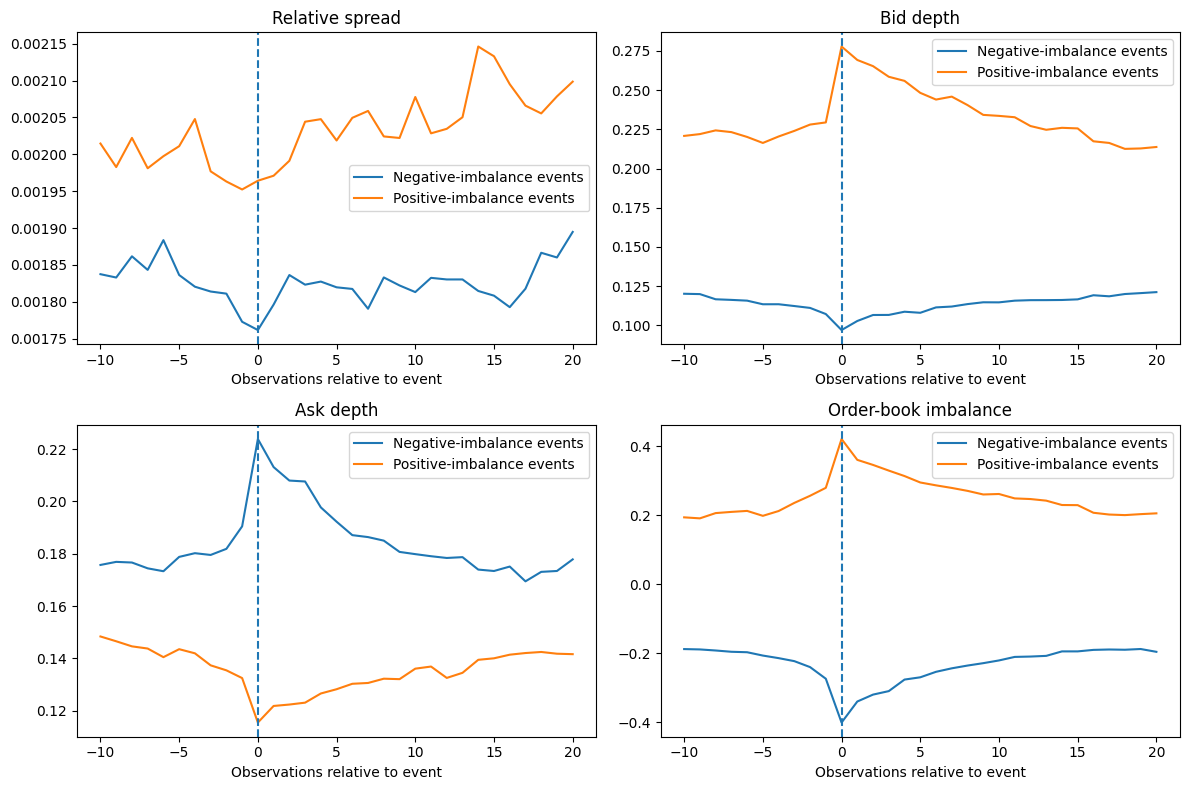

In [17]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plots = [
    ("relative_spread", "Relative spread"),
    ("bid_depth", "Bid depth"),
    ("ask_depth", "Ask depth"),
    ("imbalance", "Order-book imbalance")
]

for ax, (column, title) in zip(axes.flat, plots):
    ax.plot(
        relative_times,
        sell_profile[column],
        label="Negative-imbalance events"
    )
    ax.plot(
        relative_times,
        buy_profile[column],
        label="Positive-imbalance events"
    )
    ax.axvline(0, linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Observations relative to event")
    ax.legend()

plt.tight_layout()
plt.show()


In [18]:

# Summarize recovery at selected horizons
# Relative changes are measured from each event's own value.

def summarize_recovery(event_indices, event_name):
    rows = []

    for event in event_indices:
        base = df.iloc[event]

        for horizon in [0, 5, 10, 20]:
            future = df.iloc[event + horizon]

            rows.append({
                "Event type": event_name,
                "Horizon": horizon,
                "Abs imbalance": abs(future["imbalance"]),
                "Relative spread": future["relative_spread"],
                "Bid depth change": future["bid_depth"] - base["bid_depth"],
                "Ask depth change": future["ask_depth"] - base["ask_depth"],
                "Mid-price change": future["mid_price"] - base["mid_price"]
            })

    return pd.DataFrame(rows)

recovery = pd.concat([
    summarize_recovery(sell_events, "Negative imbalance"),
    summarize_recovery(buy_events, "Positive imbalance")
], ignore_index=True)

summary = recovery.groupby(["Event type", "Horizon"]).agg({
    "Abs imbalance": "mean",
    "Relative spread": "mean",
    "Bid depth change": "mean",
    "Ask depth change": "mean",
    "Mid-price change": "mean"
}).round(6)

display(summary)


Abs imbalance  Relative spread  Bid depth change  \
Event type         Horizon                                                     
Negative imbalance 0             0.401463         0.001762          0.000000   
                   5             0.289605         0.001820          0.011000   
                   10            0.256930         0.001813          0.017647   
                   20            0.241648         0.001895          0.024167   
Positive imbalance 0             0.421258         0.001964          0.000000   
                   5             0.308851         0.002019         -0.029538   
                   10            0.288600         0.002078         -0.044210   
                   20            0.259649         0.002098         -0.064046   

                            Ask depth change  Mid-price change  
Event type         Horizon                                      
Negative imbalance 0                0.000000          0.000000  
                   5               -0.031595         -0.000017  
                   10              -0.043993         -0.000035  
                   20              -0.045996         -0.000059  
Positive imbalance 0                0.000000          0.000000  
                   5                0.012734          0.000023  
                   10               0.020593          0.000021  
                   20               0.026131          0.000034

In [19]:

import numpy as np
import pandas as pd
from scipy import stats

def event_level_changes(event_indices, event_name):
    rows = []

    for event in event_indices:
        base = df.iloc[event]

        for h in [5, 10, 20]:
            future = df.iloc[event + h]

            rows.append({
                "Event type": event_name,
                "Horizon": h,
                "Abs imbalance change":
                    abs(future["imbalance"]) - abs(base["imbalance"]),
                "Relative spread change":
                    future["relative_spread"] - base["relative_spread"],
                "Relative spread % change":
                    (future["relative_spread"] /
                     base["relative_spread"] - 1) * 100,
                "Mid-price change":
                    future["mid_price"] - base["mid_price"]
            })

    return pd.DataFrame(rows)

changes = pd.concat([
    event_level_changes(sell_events, "Negative imbalance"),
    event_level_changes(buy_events, "Positive imbalance")
], ignore_index=True)

results = []

for (event_type, horizon), group in changes.groupby(
    ["Event type", "Horizon"]
):
    for variable in [
        "Abs imbalance change",
        "Relative spread change",
        "Relative spread % change",
        "Mid-price change"
    ]:
        x = group[variable].dropna()
        test = stats.ttest_1samp(x, popmean=0)

        results.append({
            "Event type": event_type,
            "Horizon": horizon,
            "Measure": variable,
            "Mean change": x.mean(),
            "Median change": x.median(),
            "Observations": len(x),
            "t-statistic": test.statistic,
            "p-value": test.pvalue
        })

significance_table = pd.DataFrame(results)
display(significance_table.round(6))


,Event type,Horizon,Measure,Mean change,Median change,Observations,t-statistic,p-value
0,Negative imbalance,5,Abs imbalance change,-0.111858,-0.077081,193,-10.986563,0.000000
1,Negative imbalance,5,Relative spread change,0.000058,0.000000,193,1.172555,0.242427
2,Negative imbalance,5,Relative spread % change,17.376208,0.000000,193,2.596895,0.010135
3,Negative imbalance,5,Mid-price change,-0.000017,0.000000,193,-2.214673,0.027959
4,Negative imbalance,10,Abs imbalance change,-0.144534,-0.110526,193,-13.247633,0.000000
5,Negative imbalance,10,Relative spread change,0.000051,0.000000,193,0.847628,0.397701
6,Negative imbalance,10,Relative spread % change,22.476925,0.000000,193,3.637311,0.000354
7,Negative imbalance,10,Mid-price change,-0.000035,0.000000,193,-3.144141,0.001930
8,Negative imbalance,20,Abs imbalance change,-0.159815,-0.158078,193,-15.449236,0.000000
9,Negative imbalance,20,Relative spread change,0.000133,0.000000,193,1.874401,0.062394


In [21]:
# Add the missing column to your existing DataFrame
df["abs_imbalance"] = df["imbalance"].abs()

# Verify that it exists
print(df.columns.tolist())
print(df[["imbalance", "abs_imbalance"]].head())

['mid_price', 'spread', 'relative_spread', 'bid_depth', 'ask_depth', 'imbalance', 'abs_imbalance']
   imbalance  abs_imbalance
0  -0.131111       0.131111
1  -0.063336       0.063336
2  -0.141711       0.141711
3  -0.313139       0.313139
4  -0.351552       0.351552


In [22]:

import numpy as np
import pandas as pd
from scipy import stats

def h1_test(event_indices, event_type):
    rows = []

    for event in event_indices:
        pre = df.iloc[event-10:event]
        current = df.iloc[event]

        measures = {
            "Absolute imbalance": (
                current["imbalance"] if False else current["abs_imbalance"]
            ) - pre["imbalance"].abs().mean(),
            "Relative spread": (
                current["relative_spread"]
                - pre["relative_spread"].mean()
            ),
            "Total depth deterioration": (
                pre["bid_depth"].mean() + pre["ask_depth"].mean()
                - current["bid_depth"] - current["ask_depth"]
            )
        }

        for measure, change in measures.items():
            rows.append({
                "Event type": event_type,
                "Measure": measure,
                "Change": change
            })

    results = []

    data = pd.DataFrame(rows)
    for (etype, measure), g in data.groupby(
        ["Event type", "Measure"]
    ):
        x = g["Change"].dropna()
        test = stats.ttest_1samp(x, 0)

        results.append({
            "Event type": etype,
            "Measure": measure,
            "N": len(x),
            "Mean change": x.mean(),
            "Median change": x.median(),
            "t-statistic": test.statistic,
            "p-value": test.pvalue
        })

    return pd.DataFrame(results)

h1_results = pd.concat([
    h1_test(sell_events, "Negative imbalance"),
    h1_test(buy_events, "Positive imbalance")
], ignore_index=True)

display(h1_results.round(6))


,Event type,Measure,N,Mean change,Median change,t-statistic,p-value
0,Negative imbalance,Absolute imbalance,193,0.155321,0.145767,19.329516,0.000000
1,Negative imbalance,Relative spread,193,-0.000070,-0.000000,-1.710641,0.088763
2,Negative imbalance,Total depth deterioration,193,-0.027444,-0.000731,-4.106362,0.000059
3,Positive imbalance,Absolute imbalance,172,0.161463,0.163412,17.340541,0.000000
4,Positive imbalance,Relative spread,172,-0.000031,-0.000000,-0.777544,0.437912
5,Positive imbalance,Total depth deterioration,172,-0.028959,-0.003261,-2.880618,0.004477


In [23]:

def h2_test(event_indices, event_type):
    rows = []

    for event in event_indices:
        depth_col = (
            "bid_depth" if event_type == "Negative imbalance"
            else "ask_depth"
        )
        baseline = df.iloc[event][depth_col]

        for horizon in [5, 10, 20]:
            change = df.iloc[event+horizon][depth_col] - baseline
            rows.append({
                "Event type": event_type,
                "Horizon": horizon,
                "Depth change": change
            })

    results = []
    data = pd.DataFrame(rows)

    for (etype, horizon), g in data.groupby(
        ["Event type", "Horizon"]
    ):
        x = g["Depth change"].dropna()
        test = stats.ttest_1samp(x, 0)

        results.append({
            "Event type": etype,
            "Horizon": horizon,
            "N": len(x),
            "Mean depth change": x.mean(),
            "Median depth change": x.median(),
            "t-statistic": test.statistic,
            "p-value": test.pvalue
        })

    return pd.DataFrame(results)

h2_results = pd.concat([
    h2_test(sell_events, "Negative imbalance"),
    h2_test(buy_events, "Positive imbalance")
], ignore_index=True)

display(h2_results.round(6))


,Event type,Horizon,N,Mean depth change,Median depth change,t-statistic,p-value
0,Negative imbalance,5,193,0.011000,0.003850,5.508013,0.000000
1,Negative imbalance,10,193,0.017647,0.007160,5.888793,0.000000
2,Negative imbalance,20,193,0.024167,0.010620,6.588037,0.000000
3,Positive imbalance,5,172,0.012734,0.005670,4.746374,0.000004
4,Positive imbalance,10,172,0.020593,0.007090,4.313184,0.000027
5,Positive imbalance,20,172,0.026131,0.010835,5.376299,0.000000


In [25]:
import numpy as np

df["mid_return"] = df["mid_price"].pct_change()

print(df[["mid_price", "mid_return"]].head())

   mid_price  mid_return
0    0.26870         NaN
1    0.26870    0.000000
2    0.26865   -0.000186
3    0.26865    0.000000
4    0.26865    0.000000


In [26]:

events = []

for event_type, event_indices in [
    ("Negative imbalance", sell_events),
    ("Positive imbalance", buy_events)
]:
    depth_col = (
        "bid_depth" if event_type == "Negative imbalance"
        else "ask_depth"
    )

    for event in event_indices:
        base = df.iloc[event]
        pre_mid = df.iloc[event-10:event]["mid_price"].mean()
        depth_change_5 = (
            df.iloc[event+5][depth_col] - base[depth_col]
        )
        future = df.iloc[event+20]

        events.append({
            "Event": event,
            "Event type": event_type,
            "Provision proxy": depth_change_5,
            "Abs imbalance recovery":
                abs(base["imbalance"]) - abs(future["imbalance"]),
            "Spread recovery":
                base["relative_spread"] - future["relative_spread"],
            "Depth recovery":
                future["bid_depth"] + future["ask_depth"]
                - base["bid_depth"] - base["ask_depth"],
            "Price deviation reduction":
                abs(base["mid_price"] - pre_mid)
                - abs(future["mid_price"] - pre_mid),
            "Pre-event volatility":
                df.iloc[event-10:event]["mid_return"].std(),
            "Pre-event spread":
                df.iloc[event-10:event]["relative_spread"].mean(),
            "Pre-event depth":
                df.iloc[event-10:event]["bid_depth"].mean()
                + df.iloc[event-10:event]["ask_depth"].mean()
        })

event_df = pd.DataFrame(events)

event_df["Provision group"] = np.where(
    event_df["Provision proxy"] >= event_df["Provision proxy"].median(),
    "Stronger proxy", "Weaker proxy"
)

outcomes = [
    "Abs imbalance recovery",
    "Spread recovery",
    "Depth recovery",
    "Price deviation reduction"
]

comparison = []

for (etype, outcome), group in [
    ((etype, outcome), g)
    for etype, eg in event_df.groupby("Event type")
    for outcome in outcomes
    for _, g in [(outcome, eg)]
]:
    strong = group.loc[
        group["Provision group"] == "Stronger proxy", outcome
    ].dropna()
    weak = group.loc[
        group["Provision group"] == "Weaker proxy", outcome
    ].dropna()

    if len(strong) >= 2 and len(weak) >= 2:
        test = stats.ttest_ind(strong, weak, equal_var=False)

        comparison.append({
            "Event type": etype,
            "Outcome": outcome,
            "Mean stronger": strong.mean(),
            "Mean weaker": weak.mean(),
            "Difference": strong.mean() - weak.mean(),
            "p-value": test.pvalue,
            "N stronger": len(strong),
            "N weaker": len(weak)
        })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(6))


,Event type,Outcome,Mean stronger,Mean weaker,Difference,p-value,N stronger,N weaker
0,Negative imbalance,Abs imbalance recovery,0.185463,0.135463,0.050000,0.015491,94,99
1,Negative imbalance,Spread recovery,-0.000205,-0.000065,-0.000140,0.328015,94,99
2,Negative imbalance,Depth recovery,-0.003784,-0.038963,0.035180,0.026211,94,99
3,Negative imbalance,Price deviation reduction,-0.000108,-0.000132,0.000024,0.378098,94,99
4,Positive imbalance,Abs imbalance recovery,0.178579,0.143412,0.035167,0.125220,89,83
5,Positive imbalance,Spread recovery,-0.000153,-0.000114,-0.000039,0.788797,89,83
6,Positive imbalance,Depth recovery,-0.010942,-0.066838,0.055896,0.008790,89,83
7,Positive imbalance,Price deviation reduction,-0.000126,-0.000100,-0.000027,0.340843,89,83


In [27]:

import statsmodels.api as sm

reg = event_df.copy()
reg["Positive event"] = (
    reg["Event type"] == "Positive imbalance"
).astype(int)

reg = reg.replace([np.inf, -np.inf], np.nan).dropna(
    subset=[
        "Abs imbalance recovery",
        "Provision proxy",
        "Pre-event volatility",
        "Pre-event spread",
        "Pre-event depth"
    ]
)

X = reg[[
    "Provision proxy",
    "Pre-event volatility",
    "Pre-event spread",
    "Pre-event depth",
    "Positive event"
]]
X = sm.add_constant(X)
y = reg["Abs imbalance recovery"]

model = sm.OLS(y, X).fit(cov_type="HC3")
print(model.summary())


                              OLS Regression Results                              
Dep. Variable:     Abs imbalance recovery   R-squared:                       0.007
Model:                                OLS   Adj. R-squared:                 -0.006
Method:                     Least Squares   F-statistic:                    0.5841
Date:                    Sat, 24 Oct 2026   Prob (F-statistic):              0.712
Time:                            05:34:04   Log-Likelihood:                 185.87
No. Observations:                     365   AIC:                            -359.7
Df Residuals:                         359   BIC:                            -336.3
Df Model:                               5                                         
Covariance Type:                      HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------

In [28]:

import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp

# Ensure required variables exist
df["abs_imbalance"] = df["imbalance"].abs()
df["total_depth"] = df["bid_depth"] + df["ask_depth"]

# Alternative event thresholds: 10th and 90th percentiles
lower_10 = df["imbalance"].quantile(0.10)
upper_90 = df["imbalance"].quantile(0.90)

negative_candidates = np.flatnonzero(
    df["imbalance"].to_numpy() <= lower_10
)
positive_candidates = np.flatnonzero(
    df["imbalance"].to_numpy() >= upper_90
)

negative_events_10 = select_events(negative_candidates)
positive_events_90 = select_events(positive_candidates)

print("10th/90th percentile robustness check")
print("Negative-imbalance events:", len(negative_events_10))
print("Positive-imbalance events:", len(positive_events_90))

# Measure recovery from event time to each future horizon
rows = []

for event_type, events in [
    ("Negative imbalance", negative_events_10),
    ("Positive imbalance", positive_events_90)
]:
    for horizon in [5, 10, 20]:
        abs_imb_recovery = []
        spread_recovery = []
        depth_change = []

        for i in events:
            # Positive means absolute imbalance decreased
            abs_imb_recovery.append(
                df["abs_imbalance"].iloc[i]
                - df["abs_imbalance"].iloc[i + horizon]
            )

            # Positive means spread narrowed
            spread_recovery.append(
                df["spread"].iloc[i]
                - df["spread"].iloc[i + horizon]
            )

            # Positive means total displayed depth increased
            depth_change.append(
                df["total_depth"].iloc[i + horizon]
                - df["total_depth"].iloc[i]
            )

        for outcome, values in [
            ("Absolute imbalance recovery", abs_imb_recovery),
            ("Spread recovery", spread_recovery),
            ("Total depth change", depth_change)
        ]:
            values = np.asarray(values, dtype=float)
            values = values[np.isfinite(values)]

            t_stat, p_value = ttest_1samp(values, 0)

            rows.append({
                "Event type": event_type,
                "Horizon": horizon,
                "Outcome": outcome,
                "N": len(values),
                "Mean change": values.mean(),
                "Median change": np.median(values),
                "t-statistic": t_stat,
                "p-value": p_value
            })

robustness_results = pd.DataFrame(rows)
display(robustness_results.round(6))


10th/90th percentile robustness check
Negative-imbalance events: 350
Positive-imbalance events: 323


,Event type,Horizon,Outcome,N,Mean change,Median change,t-statistic,p-value
0,Negative imbalance,5,Absolute imbalance recovery,350,0.090258,0.072765,14.112289,0.000000
1,Negative imbalance,5,Spread recovery,350,-0.000011,0.000000,-1.313614,0.189839
2,Negative imbalance,5,Total depth change,350,-0.012733,-0.000955,-2.787933,0.005595
3,Negative imbalance,10,Absolute imbalance recovery,350,0.104847,0.091991,15.552257,0.000000
4,Negative imbalance,10,Spread recovery,350,-0.000006,0.000000,-0.615818,0.538416
5,Negative imbalance,10,Total depth change,350,-0.022329,-0.001495,-4.261359,0.000026
6,Negative imbalance,20,Absolute imbalance recovery,350,0.120031,0.126617,16.989765,0.000000
7,Negative imbalance,20,Spread recovery,350,-0.000013,0.000000,-1.056208,0.291604
8,Negative imbalance,20,Total depth change,350,-0.021378,-0.003730,-3.515306,0.000497
9,Positive imbalance,5,Absolute imbalance recovery,323,0.089067,0.063782,12.480270,0.000000


In [29]:
display(
    robustness_results[
        robustness_results["Event type"] == "Positive imbalance"
    ].round(6).to_string(index=False)
)

'        Event type  Horizon                     Outcome   N  Mean change  Median change  t-statistic  p-value\nPositive imbalance        5 Absolute imbalance recovery 323     0.089067       0.063782    12.480270 0.000000\nPositive imbalance        5             Spread recovery 323     0.000005       0.000000     0.633405 0.526919\nPositive imbalance        5          Total depth change 323    -0.004003       0.000520    -0.837390 0.402994\nPositive imbalance       10 Absolute imbalance recovery 323     0.104694       0.084786    14.679672 0.000000\nPositive imbalance       10             Spread recovery 323    -0.000021       0.000000    -1.455951 0.146380\nPositive imbalance       10          Total depth change 323    -0.012067      -0.004600    -2.107509 0.035846\nPositive imbalance       20 Absolute imbalance recovery 323     0.117344       0.111687    15.713870 0.000000\nPositive imbalance       20             Spread recovery 323    -0.000017       0.000000    -1.365530 0.173040\n

In [30]:
display(
    robustness_results[
        (robustness_results["Event type"] == "Positive imbalance") &
        (robustness_results["Horizon"] == 20) &
        (robustness_results["Outcome"] == "Total depth change")
    ].round(6)
)

,Event type,Horizon,Outcome,N,Mean change,Median change,t-statistic,p-value
17,Positive imbalance,20,Total depth change,323,-0.015276,-0.00655,-2.200806,0.028459
